# 🌸❄️ Almond Sentinel: Frost Prediction

**Goal:** every evening, 2 hours after sunset, predict whether the air around an almond tree will reach **0 °C or below before 9 am** (`frost_tonight` = 1), using only the readings the node has taken so far.

**Dataset:** `frost_nights.csv`: one row per sensor node per night, 3 frost seasons (2022-23 → 2024-25), 3 sites (Sfax, Kasserine, Thala).

**Plan**
1. Load the data from Google Drive
2. Quick exploration
3. Data preparation: remove leakage columns, missing values (None), duplicates, impossible values, outliers
4. Encode categorical columns
5. Train/test split **by season** (train 2022-23 + 2023-24, test 2024-25)
6. Train and compare 9 algorithms with cross-validation
7. Tune the best algorithm
8. Choose the alarm threshold (missing a frost costs more than a false alarm)
9. Final evaluation on the unseen test season
10. Save the model and predict a new night

> **How to run:** in Colab, *Runtime → Run all*. When asked, allow access to Google Drive.
> If the dataset is in a folder that was *shared with you*, first right-click the folder in Drive → **Organize → Add shortcut → My Drive**.

## 0. Setup

In [47]:
import os, sys, glob, time, warnings, importlib, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

# XGBoost and LightGBM are pre-installed on Colab; install them if missing
for pkg in ["xgboost", "lightgbm"]:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier)
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score, recall_score,
                             precision_score, confusion_matrix, classification_report,
                             precision_recall_curve, roc_curve, mean_absolute_error)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier, LGBMRegressor
import joblib
from IPython.display import display
print("Libraries ready")

Libraries ready


## 1. Load the data from Google Drive

In [48]:
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

REL_PATH = "AOTN TSYP14 Challenge - IEEE ESPRIT SB/used data/frostdataset/frost_nights.csv"
candidates = [
    f"/content/drive/MyDrive/{REL_PATH}",      # folder in My Drive (or a shortcut to it)
    f"/content/drive/Shareddrives/{REL_PATH}", # folder is a Shared drive
    "frost_nights.csv",                        # file uploaded next to the notebook
]
DATA_PATH = next((p for p in candidates if os.path.exists(p)), None)

if DATA_PATH is None and IN_COLAB:
    print("Not found at the expected path, searching Drive (can take a minute)...")
    hits = glob.glob("/content/drive/MyDrive/**/frost_nights.csv", recursive=True) + \
           glob.glob("/content/drive/Shareddrives/**/frost_nights.csv", recursive=True)
    DATA_PATH = hits[0] if hits else None

assert DATA_PATH is not None, ("frost_nights.csv not found. Check the folder name, or add a shortcut "
                               "of the shared folder to My Drive, or upload the file to Colab.")
print("Using:", DATA_PATH)

raw = pd.read_csv(DATA_PATH, parse_dates=["date"])
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Not found at the expected path, searching Drive (can take a minute)...
Using: /content/drive/MyDrive/AOTN TSYP14 Challenge - IEEE ESPRIT SB (1)/used data/frostdataset/frost_nights.csv
54,216 rows x 68 columns


,node_id,orchard_id,site,soil_type,season,date,pheno_stage,doy,t_dec_c,rh_dec_pct,td_dec_c,dewpoint_depression_dec,t_sunset_c,rh_sunset_pct,cooling_since_sunset,cooling_last_hour,t_max_today_c,t_min_last_night_c,last_night_floor_hours,tmax_change_1d,rh_min_today,rh_at_sensor_cap,td_change_since_noon,td_change_1d,vpd_dec_kpa,tsoil_dec_c,tsoil_max_today,tsoil_minus_tair_dec,vwc_dec,sat_ratio_dec,rew_dec,light_day_mean_adc,light_saturated_hours,light_sunset_adc,piezo_rms_dec,piezo_rms_evening,piezo_rms_day,sky_emissivity_clear,lnet_clear_wm2,brunt_clear_cooling_c,brunt_clear_tmin_c,night_length_h,critical_temp_c,days_from_bloom_start,latitude,elevation_m,theta_fc,theta_wp,theta_sat,orchard_floor,node_position,doy_sin,doy_cos,floor_is_cover_crop,position_code,frost_tonight,damaging_frost_tonight,tmin_tonight_c,hours_below_0,lead_time_to_frost_h,gt_frost_type,gt_regime,gt_wind_night_ms,gt_cloud_night,gt_radiative_cooling_c,gt_advective_change_c,gt_dewpoint_dec_c,gt_t_dec_c
0,SFX-sand-N1,SFX-sand,sfax_coastal,sand,2022-23,2022-11-15,dormant_or_other,319,21.0,67.0,14.6407,6.3593,22.0,64.0,1.0,1.0,25.0,17.0,0,1.0,53.0,0.0,0.8066,2.3646,0.8207,22.9375,23.0625,1.9375,0.043,0.1000,-0.0663,3359.0000,8,4000.0,3.42,3.6800,5.9243,0.8228,62.4751,5.9775,15.0225,13.8953,NaN,-66,34.72,23,0.114,0.047,0.43,bare,low,-0.7143,0.6998,0,-1,0,0,18.05,0,NaN,none,cloudy,2.74,0.76,5.04,-1.2,16.47,21.87
1,SFX-sand-N2,SFX-sand,sfax_coastal,sand,2022-23,2022-11-15,dormant_or_other,319,22.0,72.0,16.7202,5.2798,23.0,66.0,1.0,1.0,26.0,18.0,0,1.0,56.0,0.0,0.0245,3.0309,0.7403,23.5625,23.8750,1.5625,0.036,0.0837,-0.1718,3355.5833,9,4009.0,3.64,3.7133,5.9229,0.8382,56.7044,5.5305,16.4695,13.8953,NaN,-66,34.72,23,0.114,0.047,0.43,bare,mid,-0.7143,0.6998,0,0,0,0,18.24,0,NaN,none,cloudy,2.74,0.76,5.04,-1.2,16.47,22.07
2,SFX-sand-N3,SFX-sand,sfax_coastal,sand,2022-23,2022-11-15,dormant_or_other,319,22.0,73.0,16.9375,5.0625,24.0,67.0,2.0,1.0,26.0,19.0,0,0.0,58.0,0.0,-0.9581,2.2968,0.7139,22.9375,23.1250,0.9375,0.053,0.1233,0.0844,3313.4545,8,3980.0,4.36,4.5033,6.1986,0.8399,55.9930,5.2285,16.7715,13.8953,NaN,-66,34.72,23,0.114,0.047,0.43,bare,mid,-0.7143,0.6998,0,0,0,0,18.15,0,NaN,none,cloudy,2.74,0.76,5.04,-1.2,16.47,21.98
3,SFX-sand-N4,SFX-sand,sfax_coastal,sand,2022-23,2022-11-15,dormant_or_other,319,21.0,70.0,15.3209,5.6791,23.0,64.0,2.0,2.0,26.0,18.0,0,1.0,54.0,0.0,-0.8421,1.8627,0.7461,23.3750,23.4375,2.3750,0.049,0.1140,0.0241,3364.3333,8,3990.0,4.03,4.0833,6.1129,0.8280,60.2826,5.6820,15.3180,13.8953,NaN,-66,34.72,23,0.114,0.047,0.43,bare,mid,-0.7143,0.6998,0,0,0,0,18.24,0,NaN,none,cloudy,2.74,0.76,5.04,-1.2,16.47,22.06
4,SFX-sand-N5,SFX-sand,sfax_coastal,sand,2022-23,2022-11-15,dormant_or_other,319,22.0,67.0,15.5920,6.4080,23.0,60.0,1.0,0.0,26.0,18.0,0,1.0,51.0,0.0,-0.0890,2.3960,0.8725,24.0000,24.1875,2.0000,0.037,0.0860,-0.1567,3356.8333,8,3986.0,4.05,3.7100,5.8629,0.8296,60.3938,5.8734,16.1266,13.8953,NaN,-66,34.72,23,0.114,0.047,0.43,bare,high,-0.7143,0.6998,0,1,0,0,18.32,0,NaN,none,cloudy,2.74,0.76,5.04,-1.2,16.47,22.14


## 2. Quick exploration

Target distribution:
frost_tonight
no frost    51464
frost        2752
Name: count, dtype: int64

Frost rate: 5.1%  -> the classes are imbalanced, so accuracy is misleading.


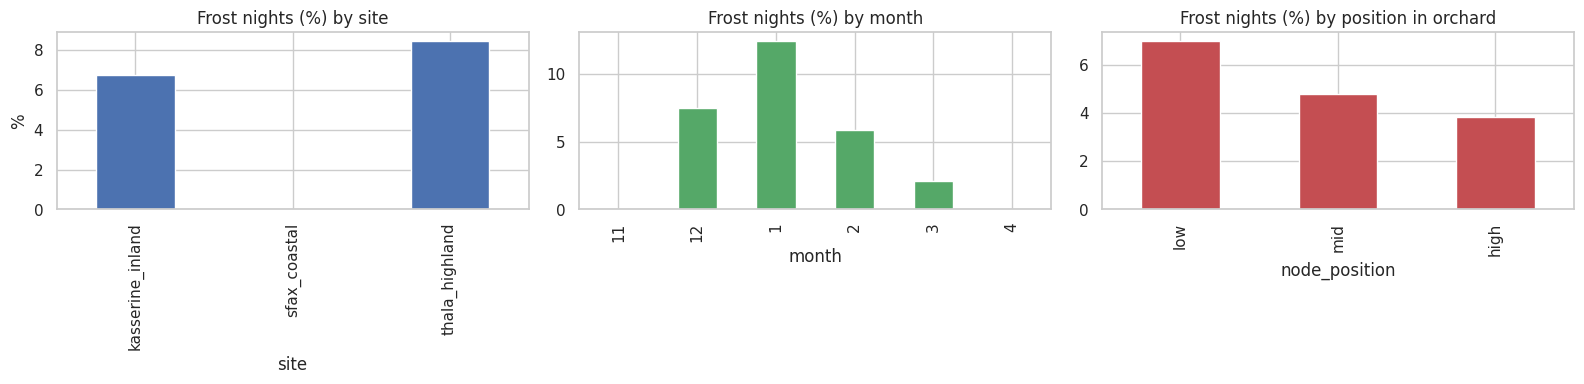

In [49]:
TARGET = "frost_tonight"
print("Target distribution:")
print(raw[TARGET].value_counts().rename({0: "no frost", 1: "frost"}))
print(f"\nFrost rate: {raw[TARGET].mean():.1%}  -> the classes are imbalanced, so accuracy is misleading.")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
raw.groupby("site")[TARGET].mean().mul(100).plot.bar(ax=ax[0], color="#4C72B0")
ax[0].set_title("Frost nights (%) by site"); ax[0].set_ylabel("%")
raw.groupby(raw["date"].dt.month)[TARGET].mean().mul(100).reindex([11, 12, 1, 2, 3, 4]).plot.bar(ax=ax[1], color="#55A868")
ax[1].set_title("Frost nights (%) by month"); ax[1].set_xlabel("month")
raw.groupby("node_position")[TARGET].mean().mul(100).reindex(["low", "mid", "high"]).plot.bar(ax=ax[2], color="#C44E52")
ax[2].set_title("Frost nights (%) by position in orchard")
plt.tight_layout(); plt.show()

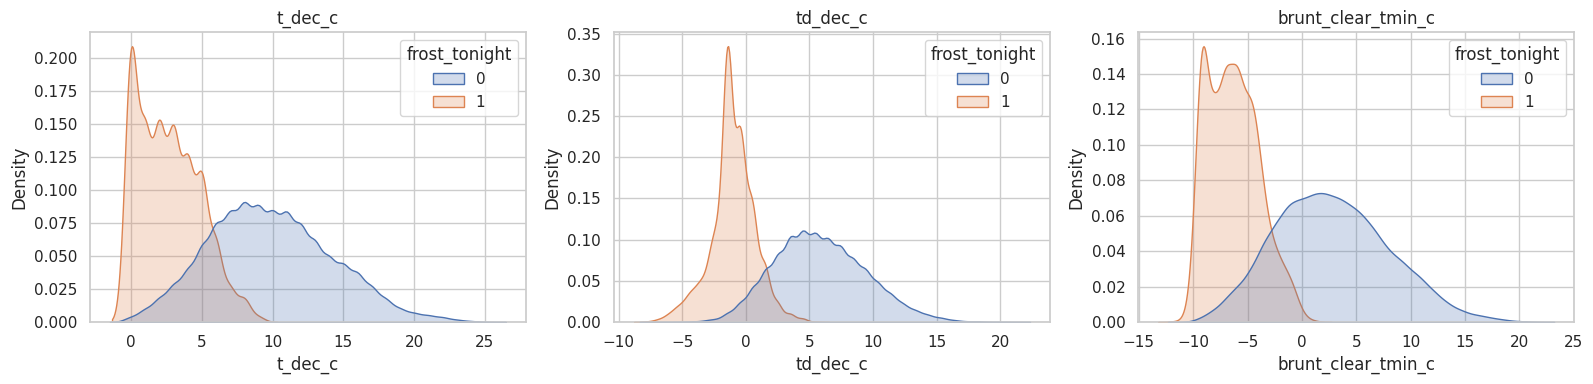

In [50]:
# How the two classic frost predictors (air temperature and dew point 2 h after sunset) separate the classes
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, col in zip(ax, ["t_dec_c", "td_dec_c", "brunt_clear_tmin_c"]):
    sns.kdeplot(data=raw, x=col, hue=TARGET, common_norm=False, fill=True, ax=a)
    a.set_title(col)
plt.tight_layout(); plt.show()

## 3. Data preparation

### 3.1 Remove leakage columns
Some columns are only known **after** the night, or are hidden simulator truth. Using them would be cheating, because the model would see the answer:
* other targets: `damaging_frost_tonight`, `tmin_tonight_c`, `hours_below_0`, `lead_time_to_frost_h`
* `gt_*` columns: hidden truth (true wind, cloud, frost type...)
* identifiers: `node_id`, `orchard_id` (we keep `season` and `date` aside, only to split the data)

In [51]:
OTHER_TARGETS = ["damaging_frost_tonight", "tmin_tonight_c", "hours_below_0", "lead_time_to_frost_h"]
GT_COLS = [c for c in raw.columns if c.startswith("gt_")]
ID_COLS = ["node_id", "orchard_id"]

df = raw.drop(columns=OTHER_TARGETS + GT_COLS + ID_COLS).copy()
df["_tmin_target"] = raw["tmin_tonight_c"]   # NOT a feature: kept only for the bonus section (step 11)
print(f"Removed {len(OTHER_TARGETS + GT_COLS + ID_COLS)} leakage/ID columns -> {df.shape[1] - 1} columns left")

Removed 14 leakage/ID columns -> 54 columns left


### 3.2 Missing values (None / NaN)
⚠️ **Do not run `df.dropna()` on the raw file.** Two kinds of empty cells exist:

| Kind | Columns | Meaning | Action |
|---|---|---|---|
| *Empty on purpose* | `critical_temp_c` | the tree is not at a frost-sensitive stage (no critical temperature) | fill with −10 °C + add a flag `sensitive_stage` |
| *Empty on purpose* | `lead_time_to_frost_h` | no frost that night | already removed (it is a target) |
| *Real missing data* | air, soil, light, piezo readings | sensor read failure / node outage | **remove the row** |

(`dropna()` on the raw file would delete every non-frost night, because `lead_time_to_frost_h` is empty on all of them.)

In [52]:
df["sensitive_stage"] = df["critical_temp_c"].notna().astype(int)
df["critical_temp_c"] = df["critical_temp_c"].fillna(-10.0)

missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("Real missing values per column:")
print(missing.to_string())

rows_before = len(df)
frost_rate_missing = df.loc[df.isna().any(axis=1), TARGET].mean()
df = df.dropna().reset_index(drop=True)
print(f"\nRemoved {rows_before - len(df):,} rows with missing sensor values "
      f"({(rows_before - len(df)) / rows_before:.1%}); frost rate in removed rows {frost_rate_missing:.1%} "
      f"vs {df[TARGET].mean():.1%} kept -> removal does not bias the classes.")

Real missing values per column:
td_change_since_noon       2126
td_change_1d               2098
cooling_since_sunset       2021
cooling_last_hour          2018
t_dec_c                    1059
rh_dec_pct                 1059
lnet_clear_wm2             1059
sky_emissivity_clear       1059
dewpoint_depression_dec    1059
td_dec_c                   1059
vpd_dec_kpa                1059
tsoil_minus_tair_dec       1059
brunt_clear_cooling_c      1059
brunt_clear_tmin_c         1059
rh_sunset_pct               989
t_sunset_c                  989
light_sunset_adc            219
tsoil_dec_c                 212
vwc_dec                     212
piezo_rms_dec               212
sat_ratio_dec               212
rew_dec                     212

Removed 5,178 rows with missing sensor values (9.6%); frost rate in removed rows 4.7% vs 5.1% kept -> removal does not bias the classes.


### 3.3 Duplicates

In [53]:
dups = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicate rows removed: {dups}")

Duplicate rows removed: 0


### 3.4 Impossible values (sensor errors)
These are **true outliers**: values the sensors cannot physically produce, or known error codes
(the DS18B20 returns **85 °C** at power-on and **−127 °C** when disconnected). Rows with such values are removed.

In [54]:
VALID_RANGES = {                      # column: (min, max)
    "t_dec_c": (-40, 60), "t_sunset_c": (-40, 60), "t_max_today_c": (-40, 60), "t_min_last_night_c": (-40, 60),
    "rh_dec_pct": (0, 100), "rh_sunset_pct": (0, 100), "rh_min_today": (0, 100),
    "tsoil_dec_c": (-20, 60), "tsoil_max_today": (-20, 60),
    "vwc_dec": (0, 0.6), "light_day_mean_adc": (0, 4095), "light_sunset_adc": (0, 4095),
    "piezo_rms_dec": (0, 100), "piezo_rms_evening": (0, 100), "piezo_rms_day": (0, 100),
    "cooling_last_hour": (-10, 10), "cooling_since_sunset": (-15, 20),
}
bad = pd.Series(False, index=df.index)
for col, (lo, hi) in VALID_RANGES.items():
    bad |= ~df[col].between(lo, hi)
for col in ["tsoil_dec_c", "tsoil_max_today"]:            # DS18B20 error codes
    bad |= df[col].isin([85.0, -127.0])
print(f"Rows with impossible sensor values removed: {bad.sum()}")
df = df[~bad].reset_index(drop=True)
print(f"Rows left: {len(df):,} | frost rate {df[TARGET].mean():.1%}")

Rows with impossible sensor values removed: 0
Rows left: 49,038 | frost rate 5.1%


### 3.5 Statistical outliers (IQR rule)
The usual rule flags values outside `[Q1 − k·IQR, Q3 + k·IQR]`. Let's look at **what** it would remove before deleting anything:

In [55]:
CATEGORICAL = ["site", "soil_type", "pheno_stage", "orchard_floor", "node_position"]
numeric_cols = [c for c in df.columns if c not in CATEGORICAL + [TARGET, "season", "date", "doy", "_tmin_target"]
                and pd.api.types.is_numeric_dtype(df[c])]
CONTINUOUS = [c for c in numeric_cols if df[c].nunique() > 15]

def iqr_flags(data, cols, k):
    q1, q3 = data[cols].quantile(0.25), data[cols].quantile(0.75)
    iqr = q3 - q1
    return (data[cols] < q1 - k * iqr) | (data[cols] > q3 + k * iqr), q1 - k * iqr, q3 + k * iqr

for k in [1.5, 3.0]:
    flags, _, _ = iqr_flags(df, CONTINUOUS, k)
    rows = flags.any(axis=1)
    print(f"k = {k}: {rows.sum():,} rows flagged ({rows.mean():.1%}) | frost rate among them "
          f"{df.loc[rows, TARGET].mean():.1%} (overall {df[TARGET].mean():.1%}) | frost nights that would be deleted: "
          f"{df.loc[rows, TARGET].sum()} of {df[TARGET].sum()}")

k = 1.5: 8,410 rows flagged (17.1%) | frost rate among them 9.2% (overall 5.1%) | frost nights that would be deleted: 777 of 2508
k = 3.0: 337 rows flagged (0.7%) | frost rate among them 22.6% (overall 5.1%) | frost nights that would be deleted: 76 of 2508


**Result:** the statistical "outliers" are mostly **real cold, dry or windy nights**: exactly the frost nights we want to predict.
Deleting them (k = 1.5) would throw away about a third of all frost examples.

**Strategy used:**
* impossible values → **removed** (3.4)
* statistical extremes → **capped** at the k = 3 fences (*winsorizing*). The fences are computed on the **training set only** (step 5), so no information leaks from the test season. Rows and frost events are kept, but extreme values can no longer dominate distance-based models such as KNN, logistic regression and MLP.

If you prefer to delete them anyway, set `OUTLIER_STRATEGY = "remove"` below. Rows are then removed from the training set only; the test season must stay untouched.

In [56]:
OUTLIER_STRATEGY = "cap"   # "cap" (recommended) or "remove"
IQR_K = 3.0

## 4. Encode categorical columns
* `soil_type`, `pheno_stage` → one-hot columns
* `site` → dropped (already described by `latitude` and `elevation_m`, which also work for a new site)
* `orchard_floor`, `node_position` → dropped (already numeric: `floor_is_cover_crop`, `position_code`)
* `doy` → dropped (already encoded as `doy_sin` / `doy_cos`)

In [57]:
data = pd.get_dummies(df, columns=["soil_type", "pheno_stage"], prefix=["soil", "stage"], dtype=int)
data = data.drop(columns=["site", "orchard_floor", "node_position", "doy"])
FEATURES = [c for c in data.columns if c not in [TARGET, "season", "date", "_tmin_target"]]
print(f"{len(FEATURES)} features:")
print(FEATURES)

56 features:
['t_dec_c', 'rh_dec_pct', 'td_dec_c', 'dewpoint_depression_dec', 't_sunset_c', 'rh_sunset_pct', 'cooling_since_sunset', 'cooling_last_hour', 't_max_today_c', 't_min_last_night_c', 'last_night_floor_hours', 'tmax_change_1d', 'rh_min_today', 'rh_at_sensor_cap', 'td_change_since_noon', 'td_change_1d', 'vpd_dec_kpa', 'tsoil_dec_c', 'tsoil_max_today', 'tsoil_minus_tair_dec', 'vwc_dec', 'sat_ratio_dec', 'rew_dec', 'light_day_mean_adc', 'light_saturated_hours', 'light_sunset_adc', 'piezo_rms_dec', 'piezo_rms_evening', 'piezo_rms_day', 'sky_emissivity_clear', 'lnet_clear_wm2', 'brunt_clear_cooling_c', 'brunt_clear_tmin_c', 'night_length_h', 'critical_temp_c', 'days_from_bloom_start', 'latitude', 'elevation_m', 'theta_fc', 'theta_wp', 'theta_sat', 'doy_sin', 'doy_cos', 'floor_is_cover_crop', 'position_code', 'sensitive_stage', 'soil_clay', 'soil_clay_loam', 'soil_loam', 'soil_loamy_sand', 'soil_sand', 'soil_sandy_loam', 'stage_bloom', 'stage_dormant_or_other', 'stage_pink_bud', 'st

## 5. Train/test split **by season**
A random split would be too optimistic: the 108 nodes measure the **same night**, so nearly identical rows would land in both train and test.
We train on two seasons and test on the third, unseen season, which is how the model will be used next year.
For cross-validation inside the training set, all rows of the **same night** stay in the same fold (`GroupKFold` grouped by date).

In [58]:
test_mask = data["season"] == "2024-25"
train, test = data[~test_mask].reset_index(drop=True), data[test_mask].reset_index(drop=True)
groups = train["date"].astype(str).values            # CV groups = nights

# outliers: fences from the TRAIN set only
flags, low_f, high_f = iqr_flags(train, CONTINUOUS, IQR_K)
if OUTLIER_STRATEGY == "remove":
    keep = ~flags.any(axis=1)
    print(f"Removing {(~keep).sum()} outlier rows from the training set "
          f"({train.loc[~keep, TARGET].sum()} of them are frost nights)")
    train, groups = train[keep].reset_index(drop=True), groups[keep.values]
else:
    print(f"Capping {flags.values.sum():,} extreme values in {flags.any(axis=1).sum():,} training rows")
train[CONTINUOUS] = train[CONTINUOUS].clip(low_f, high_f, axis=1)
test[CONTINUOUS] = test[CONTINUOUS].clip(low_f, high_f, axis=1)

X_train, y_train = train[FEATURES].astype(float), train[TARGET].values
X_test, y_test = test[FEATURES].astype(float), test[TARGET].values
print(f"Train: {len(X_train):,} nights ({y_train.mean():.1%} frost) | Test: {len(X_test):,} nights ({y_test.mean():.1%} frost)")

Capping 377 extreme values in 277 training rows
Train: 32,744 nights (5.2% frost) | Test: 16,294 nights (4.9% frost)


## 6. Train and compare algorithms

**Metric for model selection: PR-AUC (average precision).** With only ~5 % frost nights, a model that always says "no frost" gets 95 % accuracy, so accuracy is useless here.
PR-AUC measures how well the model finds frost nights without too many false alarms. We also report ROC-AUC, recall, precision and F1.

Imbalance handling: `class_weight="balanced"` (or `scale_pos_weight` for XGBoost) makes each frost night count more during training.
Models that rely on distances or gradients (logistic regression, KNN, MLP) get a `StandardScaler`.

The first row is a **reference**: logistic regression on only the two classic FAO frost predictors (air temperature and dew point 2 h after sunset).

In [59]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
scaled = lambda m: Pipeline([("scaler", StandardScaler()), ("model", m)])
plain = lambda m: Pipeline([("model", m)])

models = {
    "Logistic Regression": scaled(LogisticRegression(max_iter=2000, class_weight="balanced")),
    "KNN": scaled(KNeighborsClassifier(n_neighbors=21, weights="distance")),
    "Decision Tree": plain(DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, class_weight="balanced",
                                                  random_state=RANDOM_STATE)),
    "Random Forest": plain(RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample",
                                                  n_jobs=-1, random_state=RANDOM_STATE)),
    "Extra Trees": plain(ExtraTreesClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced",
                                              n_jobs=-1, random_state=RANDOM_STATE)),
    "Hist Gradient Boosting": plain(HistGradientBoostingClassifier(max_iter=300, learning_rate=0.06,
                                                                   class_weight="balanced", random_state=RANDOM_STATE)),
    "XGBoost": plain(XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=5, subsample=0.9,
                                   colsample_bytree=0.8, scale_pos_weight=pos_weight, eval_metric="aucpr",
                                   n_jobs=-1, random_state=RANDOM_STATE)),
    "LightGBM": plain(LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31, subsample=0.9,
                                     subsample_freq=1, colsample_bytree=0.8, class_weight="balanced",
                                     verbose=-1, random_state=RANDOM_STATE)),
    "Neural Network (MLP)": scaled(MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3, max_iter=300,
                                                 early_stopping=True, random_state=RANDOM_STATE)),
}
SCORING = {"pr_auc": "average_precision", "roc_auc": "roc_auc", "recall": "recall",
           "precision": "precision", "f1": "f1"}
cv = GroupKFold(n_splits=5)

results = []
# reference: FAO-style 2-variable model
fao_cols = ["t_dec_c", "td_dec_c"]
r = cross_validate(scaled(LogisticRegression(class_weight="balanced")), X_train[fao_cols], y_train,
                   groups=groups, cv=cv, scoring=SCORING)
results.append({"model": "Reference: FAO T + Td only", **{k: r[f"test_{k}"].mean() for k in SCORING}, "fit_s": r["fit_time"].mean()})

for name, model in models.items():
    t0 = time.time()
    r = cross_validate(model, X_train, y_train, groups=groups, cv=cv, scoring=SCORING, n_jobs=1)
    results.append({"model": name, **{k: r[f"test_{k}"].mean() for k in SCORING}, "fit_s": r["fit_time"].mean()})
    print(f"{name:<24} PR-AUC {r['test_pr_auc'].mean():.3f} ± {r['test_pr_auc'].std():.3f}   ({time.time() - t0:.0f}s)")

cv_results = pd.DataFrame(results).set_index("model").sort_values("pr_auc", ascending=False)
cv_results.round(3)

Logistic Regression      PR-AUC 0.727 ± 0.088   (10s)
KNN                      PR-AUC 0.552 ± 0.070   (18s)
Decision Tree            PR-AUC 0.536 ± 0.111   (3s)
Random Forest            PR-AUC 0.688 ± 0.047   (78s)
Extra Trees              PR-AUC 0.696 ± 0.072   (27s)
Hist Gradient Boosting   PR-AUC 0.706 ± 0.035   (12s)
XGBoost                  PR-AUC 0.707 ± 0.030   (20s)
LightGBM                 PR-AUC 0.709 ± 0.030   (20s)
Neural Network (MLP)     PR-AUC 0.721 ± 0.038   (48s)


,pr_auc,roc_auc,recall,precision,f1,fit_s
model,,,,,,
Logistic Regression,0.727,0.979,0.924,0.417,0.572,1.811
Neural Network (MLP),0.721,0.978,0.585,0.708,0.632,9.582
LightGBM,0.709,0.979,0.659,0.664,0.656,3.592
XGBoost,0.707,0.979,0.727,0.625,0.669,3.893
Hist Gradient Boosting,0.706,0.980,0.789,0.608,0.686,2.164
Extra Trees,0.696,0.978,0.699,0.624,0.654,4.914
Random Forest,0.688,0.978,0.596,0.692,0.636,15.249
Reference: FAO T + Td only,0.649,0.972,0.951,0.340,0.499,0.042
KNN,0.552,0.941,0.293,0.673,0.406,0.048


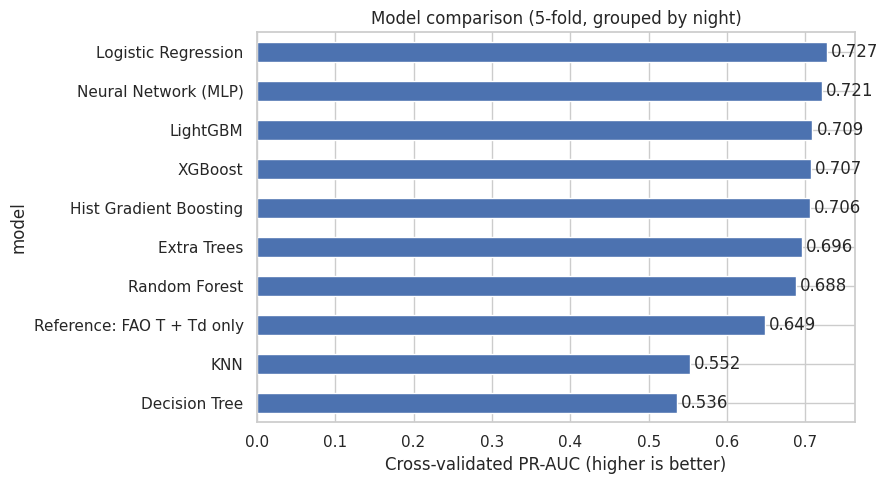

Best algorithm: Logistic Regression


In [60]:
ax = cv_results["pr_auc"].sort_values().plot.barh(figsize=(9, 5), color="#4C72B0")
ax.set_xlabel("Cross-validated PR-AUC (higher is better)"); ax.set_title("Model comparison (5-fold, grouped by night)")
for i, v in enumerate(cv_results["pr_auc"].sort_values()):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center")
plt.tight_layout(); plt.show()

BEST_NAME = cv_results.drop(index="Reference: FAO T + Td only").index[0]
print("Best algorithm:", BEST_NAME)

## 7. Tune the best algorithm
Randomized search over the main hyper-parameters of the winner, with the same night-grouped cross-validation.

In [61]:
PARAM_GRIDS = {
    "LightGBM": {"model__n_estimators": [200, 400, 700], "model__learning_rate": [0.02, 0.05, 0.1],
                 "model__num_leaves": [15, 31, 63], "model__min_child_samples": [10, 20, 50],
                 "model__colsample_bytree": [0.6, 0.8, 1.0], "model__reg_lambda": [0, 1, 5]},
    "XGBoost": {"model__n_estimators": [200, 400, 700], "model__learning_rate": [0.02, 0.05, 0.1],
                "model__max_depth": [3, 4, 6, 8], "model__min_child_weight": [1, 5, 10],
                "model__colsample_bytree": [0.6, 0.8, 1.0], "model__subsample": [0.7, 0.9, 1.0]},
    "Hist Gradient Boosting": {"model__max_iter": [200, 400, 700], "model__learning_rate": [0.02, 0.05, 0.1],
                               "model__max_leaf_nodes": [15, 31, 63], "model__min_samples_leaf": [10, 20, 50],
                               "model__l2_regularization": [0, 1, 5]},
    "Random Forest": {"model__n_estimators": [200, 400], "model__max_depth": [None, 12, 20],
                      "model__min_samples_leaf": [1, 3, 5, 10], "model__max_features": ["sqrt", 0.3, 0.5]},
    "Extra Trees": {"model__n_estimators": [200, 400], "model__max_depth": [None, 12, 20],
                    "model__min_samples_leaf": [1, 3, 5, 10], "model__max_features": ["sqrt", 0.3, 0.5]},
    "Logistic Regression": {"model__C": [0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
    "KNN": {"model__n_neighbors": [5, 11, 21, 41, 81], "model__weights": ["uniform", "distance"]},
    "Decision Tree": {"model__max_depth": [4, 6, 8, 12, None], "model__min_samples_leaf": [5, 20, 50, 100]},
    "Neural Network (MLP)": {"model__hidden_layer_sizes": [(32,), (64, 32), (128, 64)],
                             "model__alpha": [1e-4, 1e-3, 1e-2], "model__learning_rate_init": [1e-3, 3e-3]},
}
search = RandomizedSearchCV(models[BEST_NAME], PARAM_GRIDS[BEST_NAME], n_iter=15, scoring="average_precision",
                            cv=GroupKFold(n_splits=3), n_jobs=-1, random_state=RANDOM_STATE, refit=False)
t0 = time.time()
search.fit(X_train, y_train, groups=groups)
print(f"Search done in {time.time() - t0:.0f}s")
print("Best parameters:", search.best_params_)
print(f"CV PR-AUC: default {cv_results.loc[BEST_NAME, 'pr_auc']:.3f} -> tuned {search.best_score_:.3f} (3-fold)")

best_model = models[BEST_NAME].set_params(**search.best_params_)

Search done in 10s
Best parameters: {'model__C': 0.01}
CV PR-AUC: default 0.727 -> tuned 0.740 (3-fold)


## 8. Choose the alarm threshold
A model outputs a **frost probability**. The default cut-off (0.5) is not ideal: a missed bloom frost can destroy the crop, while a false alarm only costs a night of protection.
We pick the threshold that catches **90 % of frost nights** (recall ≥ 0.90). It is chosen from *out-of-fold* predictions on the training set, so the test season stays unseen.

Threshold for 90% recall: 0.664   (threshold with best F1: 0.840)


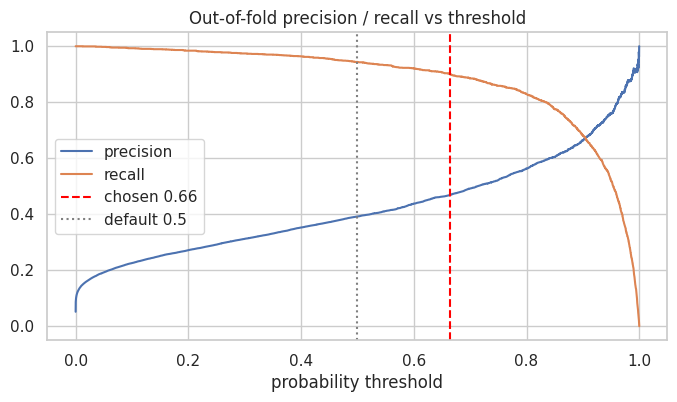

In [62]:
TARGET_RECALL = 0.90
oof = cross_val_predict(best_model, X_train, y_train, groups=groups, cv=GroupKFold(n_splits=5),
                        method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
THRESHOLD = float(np.sort(oof[y_train == 1])[int(np.floor((1 - TARGET_RECALL) * (y_train == 1).sum()))])
f1s = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-9)
BEST_F1_THR = float(thr[np.argmax(f1s)])
print(f"Threshold for {TARGET_RECALL:.0%} recall: {THRESHOLD:.3f}   (threshold with best F1: {BEST_F1_THR:.3f})")

plt.figure(figsize=(8, 4))
plt.plot(thr, prec[:-1], label="precision"); plt.plot(thr, rec[:-1], label="recall")
plt.axvline(THRESHOLD, color="red", ls="--", label=f"chosen {THRESHOLD:.2f}")
plt.axvline(0.5, color="grey", ls=":", label="default 0.5")
plt.xlabel("probability threshold"); plt.title("Out-of-fold precision / recall vs threshold"); plt.legend(); plt.show()

## 9. Final evaluation on the unseen season 2024-25

In [63]:
best_model.fit(X_train, y_train)
proba = best_model.predict_proba(X_test)[:, 1]

def summary(y, p, thr):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {"threshold": round(thr, 3), "PR-AUC": average_precision_score(y, p), "ROC-AUC": roc_auc_score(y, p),
            "recall": recall_score(y, pred), "precision": precision_score(y, pred), "F1": f1_score(y, pred),
            "false-alarm rate": fp / (fp + tn), "missed frosts": int(fn), "false alarms": int(fp)}

final = pd.DataFrame([summary(y_test, proba, 0.5), summary(y_test, proba, BEST_F1_THR), summary(y_test, proba, THRESHOLD)],
                     index=["default 0.5", "best-F1 threshold", f"recall-{TARGET_RECALL:.0%} threshold"])
print(f"Model: {BEST_NAME} (tuned)")
final.round(3)

Model: Logistic Regression (tuned)


,threshold,PR-AUC,ROC-AUC,recall,precision,F1,false-alarm rate,missed frosts,false alarms
default 0.5,0.500,0.689,0.977,0.907,0.411,0.566,0.067,74,1032
best-F1 threshold,0.840,0.689,0.977,0.718,0.568,0.634,0.028,224,434
recall-90% threshold,0.664,0.689,0.977,0.845,0.474,0.608,0.048,123,745


              precision    recall  f1-score   support

    no frost      0.992     0.952     0.971     15499
       frost      0.474     0.845     0.608       795

    accuracy                          0.947     16294
   macro avg      0.733     0.899     0.790     16294
weighted avg      0.966     0.947     0.954     16294



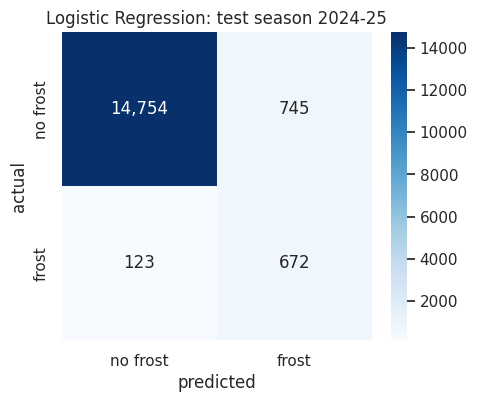

In [64]:
pred = (proba >= THRESHOLD).astype(int)
print(classification_report(y_test, pred, target_names=["no frost", "frost"], digits=3))
cm = confusion_matrix(y_test, pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", xticklabels=["no frost", "frost"], yticklabels=["no frost", "frost"])
plt.xlabel("predicted"); plt.ylabel("actual"); plt.title(f"{BEST_NAME}: test season 2024-25"); plt.show()

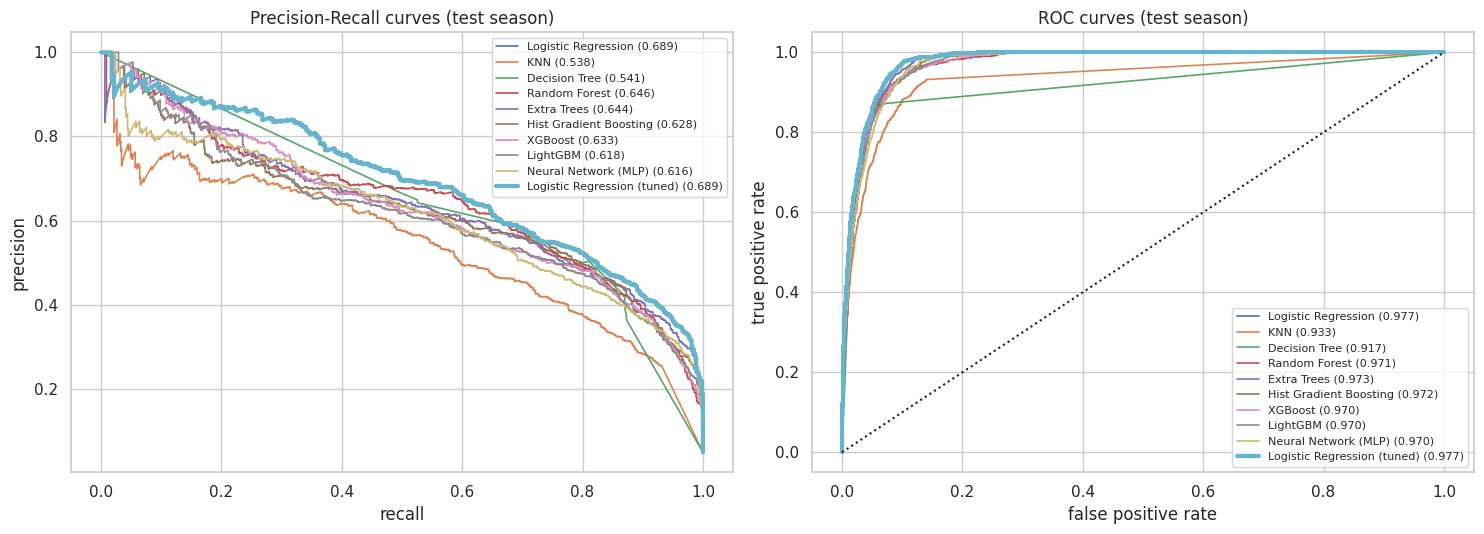

,test PR-AUC,test ROC-AUC
model,,
Logistic Regression,0.689,0.977
Logistic Regression (tuned),0.689,0.977
Random Forest,0.646,0.971
Extra Trees,0.644,0.973
XGBoost,0.633,0.970
Hist Gradient Boosting,0.628,0.972
LightGBM,0.618,0.970
Neural Network (MLP),0.616,0.970
Decision Tree,0.541,0.917


In [65]:
# All algorithms on the test season (trained on the full training set)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
test_scores = []
for name, model in list(models.items()) + [(f"{BEST_NAME} (tuned)", best_model)]:
    if not name.endswith("(tuned)"):
        model.fit(X_train, y_train)
    p = model.predict_proba(X_test)[:, 1]
    test_scores.append({"model": name, "test PR-AUC": average_precision_score(y_test, p), "test ROC-AUC": roc_auc_score(y_test, p)})
    pr, rc, _ = precision_recall_curve(y_test, p); fpr, tpr, _ = roc_curve(y_test, p)
    lw = 3 if name.endswith("(tuned)") else 1.2
    ax[0].plot(rc, pr, lw=lw, label=f"{name} ({test_scores[-1]['test PR-AUC']:.3f})")
    ax[1].plot(fpr, tpr, lw=lw, label=f"{name} ({test_scores[-1]['test ROC-AUC']:.3f})")
ax[0].set(xlabel="recall", ylabel="precision", title="Precision-Recall curves (test season)")
ax[1].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC curves (test season)")
ax[1].plot([0, 1], [0, 1], "k:")
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()
pd.DataFrame(test_scores).set_index("model").sort_values("test PR-AUC", ascending=False).round(3)

In [ ]:
# Results per site, and which features the model relies on
site_test = df.loc[df["season"] == "2024-25", "site"].values
rows = []
for s in np.unique(site_test):
    m = site_test == s
    rows.append({"site": s, "nights": m.sum(), "frost nights": int(y_test[m].sum()),
                 "caught": int(((pred == 1) & (y_test == 1))[m].sum()), "false alarms": int(((pred == 1) & (y_test == 0))[m].sum())})
display(pd.DataFrame(rows).set_index("site"))

idx = np.random.default_rng(RANDOM_STATE).choice(len(X_test), size=min(6000, len(X_test)), replace=False)
pi = permutation_importance(best_model, X_test.iloc[idx], y_test[idx], scoring="average_precision",
                            n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False).head(15)
imp.sort_values().plot.barh(figsize=(8, 6), color="#55A868")
plt.title("Top 15 features (drop in test PR-AUC when shuffled)"); plt.tight_layout(); plt.show()

## 10. Save the model and predict a new night

In [ ]:
MODEL_DIR = os.path.join(os.path.dirname(DATA_PATH), "models")
try:
    os.makedirs(MODEL_DIR, exist_ok=True)
    open(os.path.join(MODEL_DIR, ".write_test"), "w").close(); os.remove(os.path.join(MODEL_DIR, ".write_test"))
except OSError:
    MODEL_DIR = "models"; os.makedirs(MODEL_DIR, exist_ok=True)   # no write access to the shared folder

bundle = {"model": best_model, "model_name": BEST_NAME, "features": FEATURES, "threshold": THRESHOLD,
          "iqr_low": low_f, "iqr_high": high_f, "continuous": CONTINUOUS, "test_scores": final.round(4).to_dict()}
MODEL_PATH = os.path.join(MODEL_DIR, "frost_model.joblib")
joblib.dump(bundle, MODEL_PATH)
print("Saved:", MODEL_PATH)

In [66]:
def predict_frost(evening_rows: pd.DataFrame, bundle: dict) -> pd.DataFrame:
    # Same preparation as training: fill structural NaN, one-hot, cap outliers, align columns
    x = evening_rows.copy()
    x["sensitive_stage"] = x["critical_temp_c"].notna().astype(int)
    x["critical_temp_c"] = x["critical_temp_c"].fillna(-10.0)
    x = pd.get_dummies(x, columns=["soil_type", "pheno_stage"], prefix=["soil", "stage"], dtype=int)
    x = x.reindex(columns=bundle["features"], fill_value=0).astype(float)
    x[bundle["continuous"]] = x[bundle["continuous"]].clip(bundle["iqr_low"], bundle["iqr_high"], axis=1)
    p = bundle["model"].predict_proba(x)[:, 1]
    return pd.DataFrame({"frost_probability": p.round(3), "ALARM": np.where(p >= bundle["threshold"], "FROST ALERT", "-")},
                        index=evening_rows.index)

# Example: 8 evenings from the test season (4 frost nights, 4 normal nights)
loaded = joblib.load(MODEL_PATH)
sample = pd.concat([raw[(raw["season"] == "2024-25") & (raw[TARGET] == 1)].dropna(subset=["t_dec_c", "td_dec_c"]).sample(4, random_state=1),
                    raw[(raw["season"] == "2024-25") & (raw[TARGET] == 0)].dropna(subset=["t_dec_c", "td_dec_c"]).sample(4, random_state=1)])
out = predict_frost(sample, loaded)
pd.concat([sample[["site", "date", "t_dec_c", "td_dec_c"]], out,
           sample[[TARGET, "tmin_tonight_c"]].rename(columns={TARGET: "actual_frost", "tmin_tonight_c": "actual_tmin"})], axis=1)

,site,date,t_dec_c,td_dec_c,frost_probability,ALARM,actual_frost,actual_tmin
44555,kasserine_inland,2025-01-31,1.0,-1.5542,0.992,FROST ALERT,1,-2.10
44691,thala_highland,2025-02-01,5.0,-1.8801,0.969,FROST ALERT,1,-0.07
41784,thala_highland,2025-01-05,4.0,-3.9659,0.999,FROST ALERT,1,-0.29
46304,thala_highland,2025-02-16,6.0,-1.8572,0.968,FROST ALERT,1,-0.57
52531,kasserine_inland,2025-04-15,10.0,7.7696,0.000,-,0,6.71
40198,sfax_coastal,2024-12-22,7.0,3.9693,0.001,-,0,5.02
43698,kasserine_inland,2025-01-23,5.0,3.5000,0.207,-,0,3.51
47283,thala_highland,2025-02-25,5.0,3.5000,0.012,-,0,6.04


## 11. Bonus: forecast the minimum temperature + safety margin
Instead of a yes/no answer, predict **tonight's minimum temperature** and raise an alarm when it is below a margin (e.g. +1 °C).
Farmers understand "tonight −1.5 °C" better than "probability 0.73", and the margin is easy to adjust.

Tmin forecast error on the test season: MAE 0.98 °C
Alarm if forecast Tmin <= +1.1 °C -> recall 0.843, precision 0.495, F1 0.624, PR-AUC 0.727
Classifier (Logistic Regression) at its recall-90% threshold -> recall 0.845, precision 0.474, F1 0.608, PR-AUC 0.689


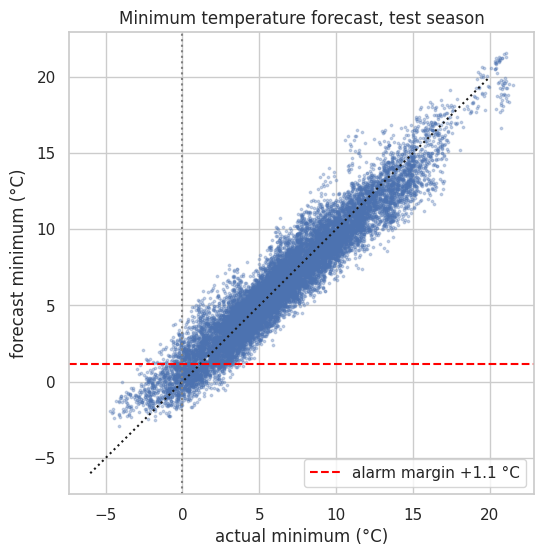

In [67]:
tmin_train, tmin_test = train["_tmin_target"].values, test["_tmin_target"].values

reg = LGBMRegressor(n_estimators=500, learning_rate=0.05, num_leaves=31, subsample=0.9, subsample_freq=1,
                    colsample_bytree=0.8, verbose=-1, random_state=RANDOM_STATE)
oof_t = cross_val_predict(reg, X_train, tmin_train, groups=groups, cv=GroupKFold(n_splits=5))
MARGIN = float(np.quantile(oof_t[y_train == 1], TARGET_RECALL))      # margin that catches 90 % of frosts
reg.fit(X_train, tmin_train)
t_pred = reg.predict(X_test)
alarm = t_pred <= MARGIN
print(f"Tmin forecast error on the test season: MAE {mean_absolute_error(tmin_test, t_pred):.2f} °C")
print(f"Alarm if forecast Tmin <= {MARGIN:+.1f} °C -> recall {recall_score(y_test, alarm):.3f}, "
      f"precision {precision_score(y_test, alarm):.3f}, F1 {f1_score(y_test, alarm):.3f}, "
      f"PR-AUC {average_precision_score(y_test, -t_pred):.3f}")
print(f"Classifier ({BEST_NAME}) at its recall-{TARGET_RECALL:.0%} threshold -> recall {final.iloc[2]['recall']:.3f}, "
      f"precision {final.iloc[2]['precision']:.3f}, F1 {final.iloc[2]['F1']:.3f}, PR-AUC {final.iloc[2]['PR-AUC']:.3f}")

plt.figure(figsize=(6, 6))
plt.scatter(tmin_test, t_pred, s=3, alpha=0.3)
plt.plot([-6, 20], [-6, 20], "k:"); plt.axhline(MARGIN, color="red", ls="--", label=f"alarm margin {MARGIN:+.1f} °C")
plt.axvline(0, color="grey", ls=":"); plt.xlabel("actual minimum (°C)"); plt.ylabel("forecast minimum (°C)")
plt.legend(); plt.title("Minimum temperature forecast, test season"); plt.show()

## 12. Conclusion
* Read the **comparison table (step 6)** and the **test results (step 9)** to report the selected algorithm and its scores.
* Key results to quote: test **PR-AUC**, **recall** (share of frost nights caught) and the **false-alarm rate** at the chosen threshold.
* The feature-importance chart (step 9) shows what drives the forecast: air humidity and dew point, how fast the air cools after sunset, the clear-sky cooling estimate (`brunt_clear_tmin_c`) and the node's position in the orchard (low spots freeze more).
* If a simple model (e.g. logistic regression) wins, that is a good sign, not a problem: the physics features already make frost almost linearly separable, and simple models transfer better to a new season.
* This dataset is synthetic (physics-based, calibrated to INM records). Before trusting the model in the field, re-train or validate it on real nights logged by your nodes.